In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix

In [2]:
data = pd.read_csv("loan_approval_data.csv")
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-null    object 
 16  Educati

In [3]:
categorical_col = data.select_dtypes(include = ["object"]).columns
num_col = data.select_dtypes(include = ["number"]).columns

# Fill the missing values

In [4]:
# Fill the missing values in numerical columns with the mean value
num_imputer = SimpleImputer(strategy = "mean")
data[num_col] = num_imputer.fit_transform(data[num_col])

# Fill the missing values in categorical columns with the most frequent value
categorical_imputer = SimpleImputer(strategy = "most_frequent")
data[categorical_col] = categorical_imputer.fit_transform(data[categorical_col])

# Exploratory Data Analysis

([<matplotlib.patches.Wedge at 0x18f36e0d010>,
 [Text(-0.6521425375337495, 0.8858386482531919, 'No'),
  Text(0.6521428261765839, -0.8858384357581341, 'Yes')],
 [Text(-0.3557141113820451, 0.48318471722901374, '70.2%'),
  Text(0.3557142688235912, -0.4831846013226186, '29.8%')])

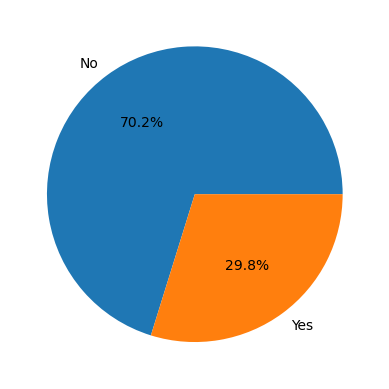

In [5]:
Loan_val_count = data["Loan_Approved"].value_counts()
fig, ax = plt.subplots()
ax.pie(
    Loan_val_count,
    labels = ["No", "Yes"],
    autopct = "%1.1f%%"
)

[Text(0, 0, '515'), Text(0, 0, '213'), Text(0, 0, '182'), Text(0, 0, '90')]

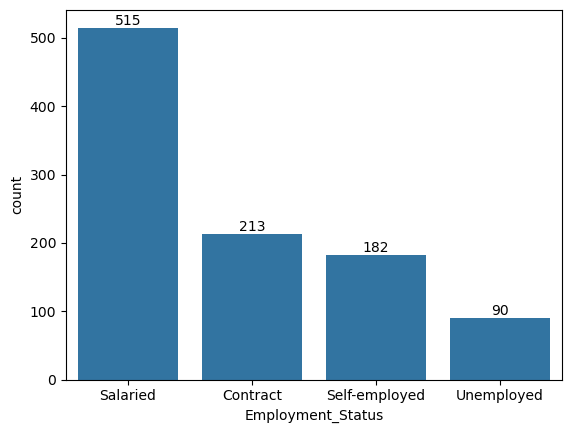

In [6]:
status_count = data["Employment_Status"].value_counts()
fig, ax = plt.subplots()
sns.barplot(
    status_count,
)
ax.bar_label(ax.containers[0])

[Text(0, 0, '722'), Text(0, 0, '278')]

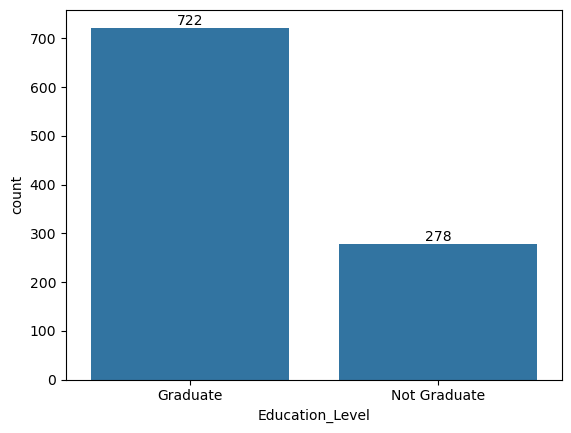

In [7]:
Education_count = data["Education_Level"].value_counts()
fig, ax = plt.subplots()
sns.barplot(
    Education_count,
)
ax.bar_label(ax.containers[0])

<Axes: xlabel='Applicant_Income', ylabel='Count'>

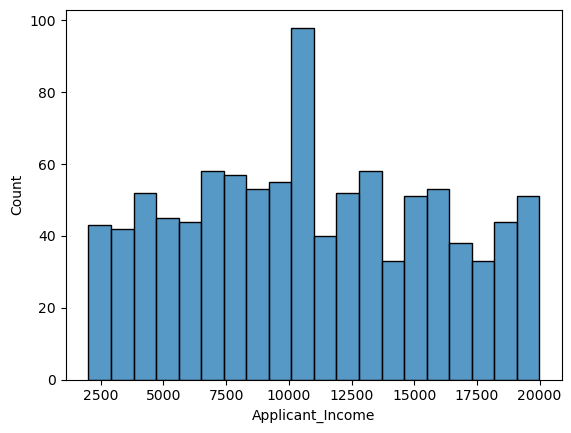

In [8]:
fig, ax = plt.subplots()
sns.histplot(
    data = data,
    x = "Applicant_Income",
    bins = 20
)

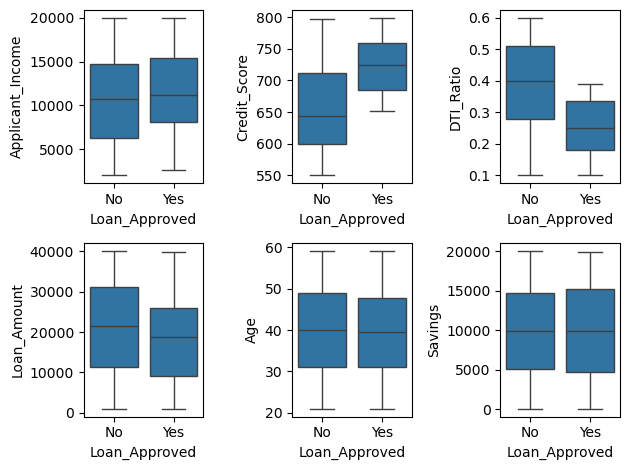

In [9]:
# To identify the outliers we use box plot
fig, ax = plt.subplots(2,3)

sns.boxplot(
    ax = ax[0][0],
    data = data,
    x = "Loan_Approved",
    y = "Applicant_Income"
)

sns.boxplot(
    ax = ax[0][1],
    data = data,
    x = "Loan_Approved",
    y = "Credit_Score"
)

sns.boxplot(
    ax = ax[0][2],
    data = data,
    x = "Loan_Approved",
    y = "DTI_Ratio"
)

sns.boxplot(
    ax = ax[1][0],
    data = data,
    x = "Loan_Approved",
    y = "Loan_Amount"
)

sns.boxplot(
    ax = ax[1][1],
    data = data,
    x = "Loan_Approved",
    y = "Age"
)

sns.boxplot(
    ax = ax[1][2],
    data = data,
    x = "Loan_Approved",
    y = "Savings"
)

fig.tight_layout()

In [10]:
# We just drop the applicant ID column beacuse it doesn't make any sense in our dataset 
data = data.drop(["Applicant_ID"], axis = 1)

In [11]:
label = LabelEncoder()
data["Education_Level"] = label.fit_transform(data["Education_Level"])
data["Loan_Approved"] = label.fit_transform(data["Loan_Approved"])
data.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,1,Female,Private,0
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,0,Male,Private,0
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,0,Female,Government,1
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,0,Female,Government,0
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,0,Male,Private,1


In [12]:
cols = ["Employment_Status", "Marital_Status", "Loan_Purpose", "Property_Area", "Gender", "Employer_Category"]
ohe = OneHotEncoder(drop = "first", sparse_output = False, handle_unknown = "ignore")
encoded = ohe.fit_transform(data[cols])
encoded_data = pd.DataFrame(encoded, columns = ohe.get_feature_names_out(cols), index = data.index)
df = pd.concat([data.drop(columns = cols), encoded_data], axis = 1)

# Correlation Heatmap

<Axes: >

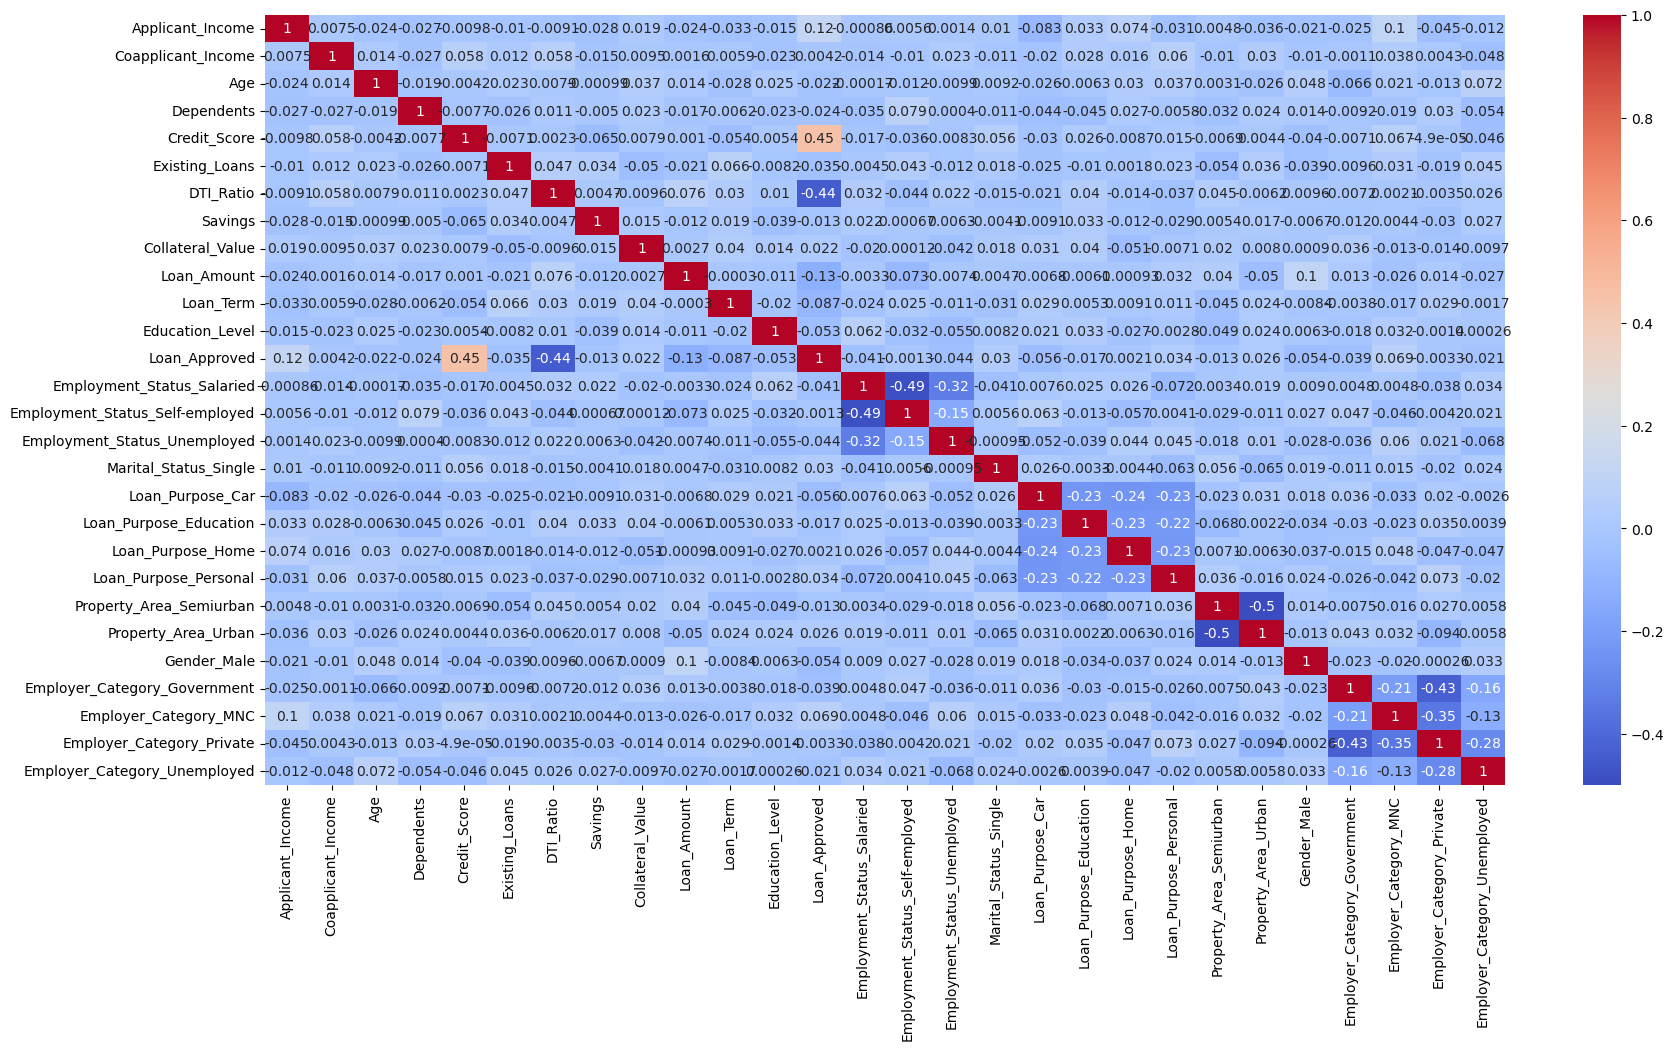

In [13]:
number_cols = df.select_dtypes(include = "number")
corr_matrix = number_cols.corr()
fig, ax = plt.subplots(figsize = (20,10))
sns.heatmap(
    corr_matrix,
    cmap = "coolwarm",
    annot = True
)

In [14]:
number_cols.corr()["Loan_Approved"].sort_values(ascending=False)

Loan_Approved                      1.000000
Credit_Score                       0.451175
Applicant_Income                   0.119796
Employer_Category_MNC              0.069049
Loan_Purpose_Personal              0.034043
Marital_Status_Single              0.030182
Property_Area_Urban                0.025963
Collateral_Value                   0.021868
Coapplicant_Income                 0.004230
Loan_Purpose_Home                  0.002118
Employment_Status_Self-employed   -0.001337
Employer_Category_Private         -0.003347
Property_Area_Semiurban           -0.012967
Savings                           -0.013437
Loan_Purpose_Education            -0.016684
Employer_Category_Unemployed      -0.021468
Age                               -0.022343
Dependents                        -0.023811
Existing_Loans                    -0.034794
Employer_Category_Government      -0.039187
Employment_Status_Salaried        -0.041428
Employment_Status_Unemployed      -0.044464
Education_Level                 

# Logistic Regression

In [15]:
# train-test-split
X = df.drop("Loan_Approved", axis = 1)
y = df["Loan_Approved"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state=42
)

# scalling the data
scalar = StandardScaler()

X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.transform(X_test)

# Create the model
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
print("Logistic Regression Model")
print("Precision of the model is: ", precision_score(y_test, y_pred))
print("Recall of the model is: ", recall_score(y_test, y_pred))
print("F1 of the model is: ", f1_score(y_test, y_pred))
print("Accuracy of the model is: ", accuracy_score(y_test, y_pred))
print("Confusion Matrix of the model is: \n", confusion_matrix(y_test, y_pred))

Logistic Regression Model
Precision of the model is:  0.7833333333333333
Recall of the model is:  0.7704918032786885
F1 of the model is:  0.7768595041322314
Accuracy of the model is:  0.865
Confusion Matrix of the model is: 
 [[126  13]
 [ 14  47]]


# kNN

In [16]:
# train-test-split
X = df.drop("Loan_Approved", axis = 1)
y = df["Loan_Approved"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42
)

# scalling the data
scalar = StandardScaler()
X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.transform(X_test)

# Model create
knn_classer = KNeighborsClassifier(n_neighbors = 5)
knn_classer.fit(X_train_scaled, y_train)

y_pred = knn_classer.predict(X_test_scaled)

print("KNN Model")
print("Precision of the model is: ", precision_score(y_test, y_pred))
print("Recall of the model is: ", recall_score(y_test, y_pred))
print("F1 of the model is: ", f1_score(y_test, y_pred))
print("Accuracy of the model is: ", accuracy_score(y_test, y_pred))
print("Confusion Matrix of the model is: \n", confusion_matrix(y_test, y_pred))

KNN Model
Precision of the model is:  0.6274509803921569
Recall of the model is:  0.5245901639344263
F1 of the model is:  0.5714285714285714
Accuracy of the model is:  0.76
Confusion Matrix of the model is: 
 [[120  19]
 [ 29  32]]


# Naive Bayes

In [17]:
from sklearn.naive_bayes import GaussianNB

# train-test-split
X = df.drop("Loan_Approved", axis = 1)
y = df["Loan_Approved"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42
)

# scalling the data
scalar = StandardScaler()
X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.transform(X_test)

# Model create
naive_model = GaussianNB()
naive_model.fit(X_train_scaled, y_train)

y_pred = naive_model.predict(X_test_scaled)

print("Naive Bayes Model")
print("Precision of the model is: ", precision_score(y_test, y_pred))
print("Recall of the model is: ", recall_score(y_test, y_pred))
print("F1 of the model is: ", f1_score(y_test, y_pred))
print("Accuracy of the model is: ", accuracy_score(y_test, y_pred))
print("Confusion Matrix of the model is: \n", confusion_matrix(y_test, y_pred))

Naive Bayes Model
Precision of the model is:  0.8035714285714286
Recall of the model is:  0.7377049180327869
F1 of the model is:  0.7692307692307693
Accuracy of the model is:  0.865
Confusion Matrix of the model is: 
 [[128  11]
 [ 16  45]]


In [18]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Gaussian Naive Bayes"
    ],
    "Accuracy": [
        0.865,
        0.760,
        0.865
    ],
    "Precision": [
        0.7833,
        0.6274,
        0.8035
    ],
    "Recall": [
        0.7705,
        0.5246,
        0.7377
    ],
    "F1-Score": [
        0.7769,
        0.5714,
        0.7692
    ]
})

comparison
comparison.style.format({
    "Accuracy": "{:.2%}",
    "Precision": "{:.2%}",
    "Recall": "{:.2%}",
    "F1-Score": "{:.2%}"
})

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,86.50%,78.33%,77.05%,77.69%
1,KNN,76.00%,62.74%,52.46%,57.14%
2,Gaussian Naive Bayes,86.50%,80.35%,73.77%,76.92%


In [19]:
best_model = comparison.loc[comparison["Precision"].idxmax(), "Model"]
print("Best Model based on Recall:", best_model)

Best Model based on Recall: Gaussian Naive Bayes


# # For this dataset Naive Bayes is the best model on the basis of precision

# Feature Engineering

In [20]:
df["Credit_Score_sq"] = df["Credit_Score"] ** 2
df["DTI_Ratio_sq"] = df["DTI_Ratio"] ** 2
#df["Applicant_Income_log"] = np.log1p(df["Applicant_Income"])
X = df.drop(columns = ["Loan_Approved", "DTI_Ratio", "Credit_Score"])
y = df["Loan_Approved"]

# Logistic Regreesion

In [21]:
# train-test-split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42
)

#Scalling the data
scalar = StandardScaler()
X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.transform(X_test)

# Model create
log_model = LogisticRegression()
log_model.fit(X_train_scaled, y_train)

y_pred_lr = log_model.predict(X_test_scaled)
print("Logistic Regression Model")
print("Precision of the model is: ", precision_score(y_test, y_pred_lr))
print("Recall of the model is: ", recall_score(y_test, y_pred_lr))
print("F1 of the model is: ", f1_score(y_test, y_pred_lr))
print("Accuracy of the model is: ", accuracy_score(y_test, y_pred_lr))
print("Confusion Matrix of the model is: \n", confusion_matrix(y_test, y_pred_lr))

Logistic Regression Model
Precision of the model is:  0.7903225806451613
Recall of the model is:  0.8032786885245902
F1 of the model is:  0.7967479674796748
Accuracy of the model is:  0.875
Confusion Matrix of the model is: 
 [[126  13]
 [ 12  49]]


# kNN

In [22]:
# train-test-split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42
)

# scalling the data
scalar = StandardScaler()
X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.transform(X_test)

# model ctrate
knn_classer = KNeighborsClassifier(n_neighbors = 5)
knn_classer.fit(X_train_scaled, y_train)

y_pred_knn = knn_classer.predict(X_test_scaled)

print("KNN Model")
print("Precision of the model is: ", precision_score(y_test, y_pred_knn))
print("Recall of the model is: ", recall_score(y_test, y_pred_knn))
print("F1 of the model is: ", f1_score(y_test, y_pred_knn))
print("Accuracy of the model is: ", accuracy_score(y_test, y_pred_knn))
print("Confusion Matrix of the model is: \n", confusion_matrix(y_test, y_pred_knn))

KNN Model
Precision of the model is:  0.62
Recall of the model is:  0.5081967213114754
F1 of the model is:  0.5585585585585585
Accuracy of the model is:  0.755
Confusion Matrix of the model is: 
 [[120  19]
 [ 30  31]]


# Naive Bayes

In [23]:
# train-test-split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42
)

# scalling the data
scalar = StandardScaler()
X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.transform(X_test)

# model crate
naive_model = GaussianNB()
naive_model.fit(X_train_scaled, y_train)

y_pred_nb = naive_model.predict(X_test_scaled)

print("Naive Bayes Model")
print("Precision of the model is: ", precision_score(y_test, y_pred_nb))
print("Recall of the model is: ", recall_score(y_test, y_pred_nb))
print("F1 of the model is: ", f1_score(y_test, y_pred_nb))
print("Accuracy of the model is: ", accuracy_score(y_test, y_pred_nb))
print("Confusion Matrix of the model is: \n", confusion_matrix(y_test, y_pred_nb))

Naive Bayes Model
Precision of the model is:  0.7833333333333333
Recall of the model is:  0.7704918032786885
F1 of the model is:  0.7768595041322314
Accuracy of the model is:  0.865
Confusion Matrix of the model is: 
 [[126  13]
 [ 14  47]]


In [24]:
# Comparison
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Gaussian Naive Bayes"
    ],
    "Accuracy": [
        0.880,
        0.785,
        0.860
    ],
    "Precision": [
        0.7846,
        0.6730,
        0.8113
    ],
    "Recall": [
        0.8360,
        0.5737,
        0.7049
    ],
    "F1-Score": [
        0.8095,
        0.6194,
        0.7543
    ]
})

comparison
comparison.style.format({
    "Accuracy": "{:.2%}",
    "Precision": "{:.2%}",
    "Recall": "{:.2%}",
    "F1-Score": "{:.2%}"
})

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,88.00%,78.46%,83.60%,80.95%
1,KNN,78.50%,67.30%,57.37%,61.94%
2,Gaussian Naive Bayes,86.00%,81.13%,70.49%,75.43%


# After using feature engineering Naive Bayes is still the best model for this dataset

# Random forest classifier

In [25]:
from sklearn.ensemble import RandomForestClassifier

# Initialize and train the Random Forest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test_scaled)

# Print results
print("Random Forest Model")
print("Precision of the model is: ", precision_score(y_test, y_pred_rf))
print("Recall of the model is: ", recall_score(y_test, y_pred_rf))
print("F1 of the model is: ", f1_score(y_test, y_pred_rf))
print("Accuracy of the model is: ", accuracy_score(y_test, y_pred_rf))
print("Confusion Matrix of the model is: \n", confusion_matrix(y_test, y_pred_rf))

Random Forest Model
Precision of the model is:  0.828125
Recall of the model is:  0.8688524590163934
F1 of the model is:  0.848
Accuracy of the model is:  0.905
Confusion Matrix of the model is: 
 [[128  11]
 [  8  53]]


In [26]:
import pandas as pd

# Updated comparison table including Random Forest
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN", "Gaussian Naive Bayes", "Random Forest"],
    "Accuracy": [0.880, 0.785, 0.860, 0.905],
    "Precision": [0.7846, 0.6730, 0.8113, 0.8281],
    "Recall": [0.8360, 0.5737, 0.7049, 0.8689],
    "F1-Score": [0.8095, 0.6194, 0.7543, 0.8480]
})

# Display with percentage formatting
comparison.style.format({
    "Accuracy": "{:.2%}",
    "Precision": "{:.2%}",
    "Recall": "{:.2%}",
    "F1-Score": "{:.2%}"
})

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,88.00%,78.46%,83.60%,80.95%
1,KNN,78.50%,67.30%,57.37%,61.94%
2,Gaussian Naive Bayes,86.00%,81.13%,70.49%,75.43%
3,Random Forest,90.50%,82.81%,86.89%,84.80%


# After comparing Random Forest vs other models, Random Forest is the best-performing model overall, achieving the highest scores across all metrics.

In [27]:
from sklearn.model_selection import cross_val_score

# 1. Initialize the models
# Note: Adjust the parameters if you used specific ones in your earlier cells
models = {
    "Logistic Regression": LogisticRegression(),
    "KNN": KNeighborsClassifier(),
    "Gaussian Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

# List to store the results
cv_results = []

# 2. Perform 5-fold cross-validation for each model
for name, model in models.items():
    # cv=5 specifies 5 folds. We are using accuracy as the scoring metric.
    # Note: You can replace X_train_scaled and y_train with your full dataset variables (e.g., X, y) 
    # if you want to cross-validate across the entire dataset rather than just the training set.
    scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='accuracy')
    
    cv_results.append({
        "Model": name,
        "Mean CV Accuracy": np.mean(scores),
        "Std Dev": np.std(scores)
    })

# 3. Create a DataFrame for easy comparison
cv_df = pd.DataFrame(cv_results)

# 4. Display the results with percentage formatting
cv_df.style.format({
    "Mean CV Accuracy": "{:.2%}",
    "Std Dev": "{:.4f}"
})

,Model,Mean CV Accuracy,Std Dev
0,Logistic Regression,85.50%,0.0108
1,KNN,78.12%,0.0314
2,Gaussian Naive Bayes,86.12%,0.0423
3,Random Forest,92.88%,0.0075


# Random Forest is dominating with a 93.62% Mean CV Accuracy. Furthermore, its low standard deviation (0.0092) indicates that it is highly consistent and stable across all the different data splits. It's definitely your strongest candidate.

In [28]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# 1. Define the grid of parameters to search
# Feel free to adjust these ranges based on how long you want the search to take!
param_grid = {
    'n_estimators': [100, 200, 300],      # Number of trees in the forest
    'max_depth': [None, 10, 20],          # Maximum depth of the trees
    'min_samples_split': [2, 5, 10],      # Minimum samples required to split an internal node
    'min_samples_leaf': [1, 2, 4]         # Minimum samples required to be at a leaf node
}

# 2. Initialize the base model
rf_base = RandomForestClassifier(random_state=42)

# 3. Set up GridSearchCV
# cv=5 matches your previous 5-fold cross-validation
# n_jobs=-1 tells your computer to use all available CPU cores to speed up the training
# verbose=1 will print out the progress as it runs
grid_search = GridSearchCV(estimator=rf_base, param_grid=param_grid, 
                           cv=5, scoring='accuracy', n_jobs=-1, verbose=1)

# 4. Fit the grid search to your data
# Note: Ensure X_train_scaled and y_train match your actual variable names
print("Starting grid search... this might take a minute or two!")
grid_search.fit(X_train_scaled, y_train)

# 5. Display the optimal results
print("\n--- Tuning Results ---")
print("Best Parameters found: ", grid_search.best_params_)
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_:.2%}")

# 6. Save the optimized model so you can use it for predictions later
best_rf_model = grid_search.best_estimator_

Starting grid search... this might take a minute or two!
Fitting 5 folds for each of 81 candidates, totalling 405 fits

--- Tuning Results ---
Best Parameters found:  {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 300}
Best Cross-Validation Accuracy: 93.75%


--- Final Model Performance on Test Set ---
              precision    recall  f1-score   support

           0       0.93      0.93      0.93       139
           1       0.84      0.85      0.85        61

    accuracy                           0.91       200
   macro avg       0.89      0.89      0.89       200
weighted avg       0.91      0.91      0.91       200



<Figure size 800x600 with 0 Axes>

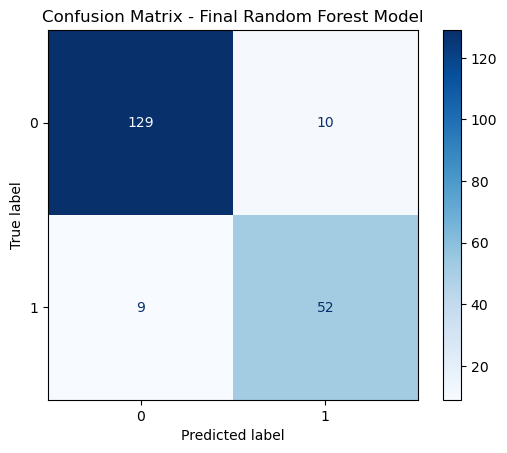

In [31]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Make predictions on your hold-out test set
y_pred = best_rf_model.predict(X_test_scaled)

# 2. Print the classification report
print("--- Final Model Performance on Test Set ---")
print(classification_report(y_test, y_pred))

# 3. Plot a confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_rf_model.classes_)

plt.figure(figsize=(8, 6))
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Final Random Forest Model')
plt.show()

In [32]:
import joblib
# Save your optimized Random Forest model to a file
joblib.dump(best_rf_model, 'tuned_loan_model.pkl')
print("Model saved successfully as 'tuned_loan_model.pkl'!")

Model saved successfully as 'tuned_loan_model.pkl'!


In [33]:
list(X_train.columns)

['Applicant_Income',
 'Coapplicant_Income',
 'Age',
 'Dependents',
 'Existing_Loans',
 'Savings',
 'Collateral_Value',
 'Loan_Amount',
 'Loan_Term',
 'Education_Level',
 'Employment_Status_Salaried',
 'Employment_Status_Self-employed',
 'Employment_Status_Unemployed',
 'Marital_Status_Single',
 'Loan_Purpose_Car',
 'Loan_Purpose_Education',
 'Loan_Purpose_Home',
 'Loan_Purpose_Personal',
 'Property_Area_Semiurban',
 'Property_Area_Urban',
 'Gender_Male',
 'Employer_Category_Government',
 'Employer_Category_MNC',
 'Employer_Category_Private',
 'Employer_Category_Unemployed',
 'Credit_Score_sq',
 'DTI_Ratio_sq']